In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Load the real dataset

In [2]:
tips = pd.read_csv(r"D:\DataScience_with_Python\Week6\tips.csv")
print("Dataset shape:", tips.shape)

Dataset shape: (244, 7)


# Display the dataset

In [3]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


# Check missing values and categories

In [4]:
print(tips.isnull().sum())
print(tips["time"].value_counts())

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64
time
Dinner    176
Lunch      68
Name: count, dtype: int64


This helps us understand the data before performing the tests.

# T-Test

## Is there a difference between average lunch and dinner bills?

H₀ (Null Hypothesis): Average lunch and dinner bills are equal.

H₁ (Alternative Hypothesis): Average lunch and dinner bills are different.

## Separate lunch and dinner data

In [5]:
lunch = tips[tips["time"] == "Lunch"]["total_bill"]

dinner = tips[tips["time"] == "Dinner"]["total_bill"]

print("Lunch observations:", len(lunch))
print("Dinner observations:", len(dinner))

Lunch observations: 68
Dinner observations: 176


## Calculate average bills

In [6]:
print("Average lunch bill:", lunch.mean())
print("Average dinner bill:", dinner.mean())

Average lunch bill: 17.168676470588235
Average dinner bill: 20.79715909090909


## Visualize the differences

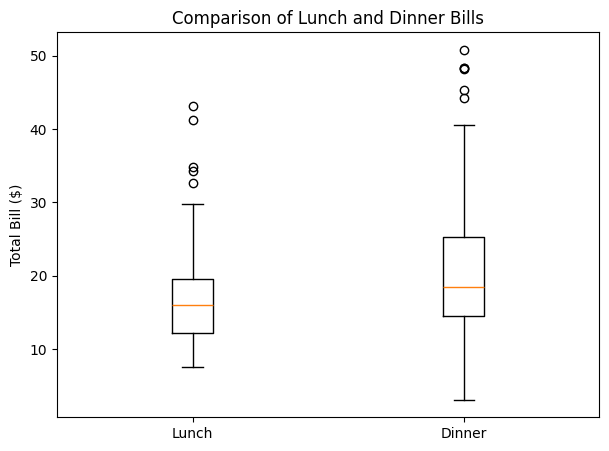

In [7]:
plt.figure(figsize=(7, 5))

plt.boxplot([lunch, dinner])

plt.xticks([1, 2], ["Lunch", "Dinner"])
plt.ylabel("Total Bill ($)")
plt.title("Comparison of Lunch and Dinner Bills")

plt.show()

## Perform Welch's T-Test

In [8]:
t_stat, p_value = stats.ttest_ind(lunch, dinner, equal_var=False)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: -3.122986183296264
P-value: 0.0021665735148038933


## Calculate a 95% confidence interval

In [9]:
t_result = stats.ttest_ind(lunch, dinner, equal_var=False)

confidence_interval = t_result.confidence_interval(confidence_level=0.95)

print("95% Confidence Interval:", confidence_interval)

95% Confidence Interval: ConfidenceInterval(low=np.float64(-5.925088453244516), high=np.float64(-1.3318767873971962))


The estimated difference is lunch minus dinner, and its 95% confidence interval is approximately -$5.93 to -$1.33.

## Interpret the T-Test

In [10]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
    print("There is a significant difference between")
    print("average lunch and dinner bills.")
else:
    print("Do not reject the null hypothesis.")
    print("There is not enough evidence of a difference.")

Reject the null hypothesis.
There is a significant difference between
average lunch and dinner bills.


Since p = 0.0022 is less than 0.05, we conclude that average lunch and dinner bills differ significantly in this dataset.

# Chi-Square Test

## Is smoking status related to whether a customer visits at lunch or dinner?

H₀ (Null Hypothesis): Smoking status and meal time are not related.

H₁ (Alternative Hypothesis): Smoking status and meal time are related.

## Create a contingency table

In [11]:
table = pd.crosstab(tips["time"], tips["smoker"])
print(table)

smoker   No  Yes
time            
Dinner  106   70
Lunch    45   23


## Perform Chi-Square Test

In [12]:
chi_stat, chi_p, dof, expected = stats.chi2_contingency(table, correction=False)

print("Chi-square statistic:", chi_stat)
print("P-value:", chi_p)
print("Degrees of freedom:", dof)

Chi-square statistic: 0.7359839393215878
P-value: 0.3909504105377676
Degrees of freedom: 1


We use correction=False for the standard uncorrected Pearson Chi-Square Test.

## Display expected frequencies

In [13]:
expected_df = pd.DataFrame(expected, index=table.index, columns=table.columns)
print(expected_df)

smoker          No        Yes
time                         
Dinner  108.918033  67.081967
Lunch    42.081967  25.918033


The expected values show what the counts would look like if smoking status and meal time were independent.

# Visualize the categorical data

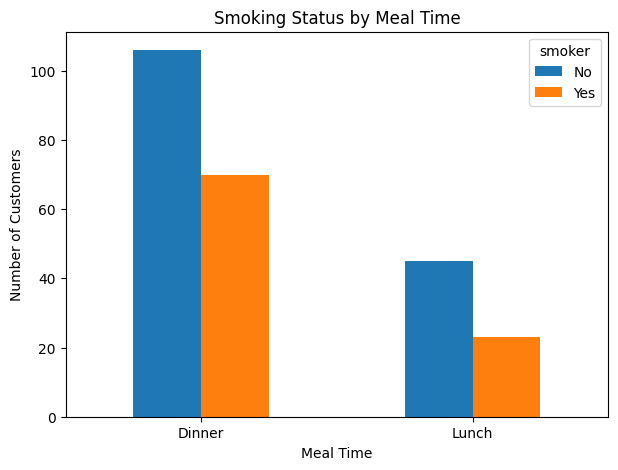

In [14]:
table.plot(kind="bar", figsize=(7, 5))

plt.title("Smoking Status by Meal Time")
plt.xlabel("Meal Time")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.show()

# Interpret the Chi-Square Test

In [15]:
alpha = 0.05

if chi_p < alpha:
    print("Reject the null hypothesis.")
    print("Smoking status and meal time are related.")
else:
    print("Do not reject the null hypothesis.")
    print("There is not enough evidence to say")
    print("smoking status and meal time are related.")

Do not reject the null hypothesis.
There is not enough evidence to say
smoking status and meal time are related.


Since p = 0.3910 is greater than 0.05, we do not have enough evidence to conclude that smoking status and meal time are related.

# Final results and conclusion

In [16]:
print("WEEK 6: HYPOTHESIS TESTING RESULTS")

print("\nT-Test Results")
print("T-statistic:", round(t_stat, 4))
print("P-value:", round(p_value, 4))

print("\nChi-Square Test Results")
print("Chi-square statistic:", round(chi_stat, 4))
print("P-value:", round(chi_p, 4))

WEEK 6: HYPOTHESIS TESTING RESULTS

T-Test Results
T-statistic: -3.123
P-value: 0.0022

Chi-Square Test Results
Chi-square statistic: 0.736
P-value: 0.391


### Conclusion

In this assignment, I used a real restaurant dataset containing 244 observations to perform a T-Test and a Chi-Square Test.

T-Test: The p-value was 0.0022, which is less than 0.05. This shows a statistically significant difference between average lunch and dinner bills.

Chi-Square Test: The p-value was 0.3910, which is greater than 0.05. This means there is not enough evidence to conclude that smoking status and meal time are related.

Overall: Hypothesis testing helps us analyze sample data and decide whether observed differences or relationships are statistically significant.

These findings describe the available restaurant data. They do not prove cause and effect, and the results may not represent all restaurants.